# Credential Brute-Force Analysis
In this notebook, we analyse the authentication attempts captured by the honeypots. Our primary focus is on **Sensor 2**, which was explicitly configured to only accept credentials from specific, non-trivial IoT credentials.

#### 1. Setup and Data Merging
The `auth` table contains the usernames and passwords, but the `sessions` table contains the sensor IDs. We first combine this data with pandas and then apply the date filter (Jan 3 - Feb 1).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Loading cached data...")
df_sessions = pd.read_pickle('../data/cache/sessions.pkl')
df_auth = pd.read_pickle('../data/cache/auth.pkl')

df_sessions['starttime'] = pd.to_datetime(df_sessions['starttime']) # Convert to pandas datetime

# Merge the auth table with the sessions table to get the 'sensor' and 'starttime' columns
# auth['session'] is the foreign key to sessions['id']
df_merged = pd.merge(
    df_auth,
    df_sessions[['id', 'sensor', 'starttime']],
    left_on='session',
    right_on='id',
    how='inner'
)

# Apply the date filter for Sensors 1 and 2
start_date = '2026-01-03'
end_date = '2026-02-01'
mask = (df_sessions['starttime'] >= start_date) & (df_sessions['starttime'] <= end_date) & (df_sessions['sensor'].astype(str).isin(['1', '2']))
df_filtered_auth = df_merged.loc[mask].copy()

print(f"Total authentication attempts in active window: {len(df_filtered_auth):,}")

Loading cached data...
Total authentication attempts in active window: 2,607,894


#### 2. Overall Top Credentials
Automated scanners constantly scan cloud IP ranges and attack them with generic credentials. Before filtering for specific sensors, we can observe the top Username/Password combinations attempted across both sensors 1 and 2.

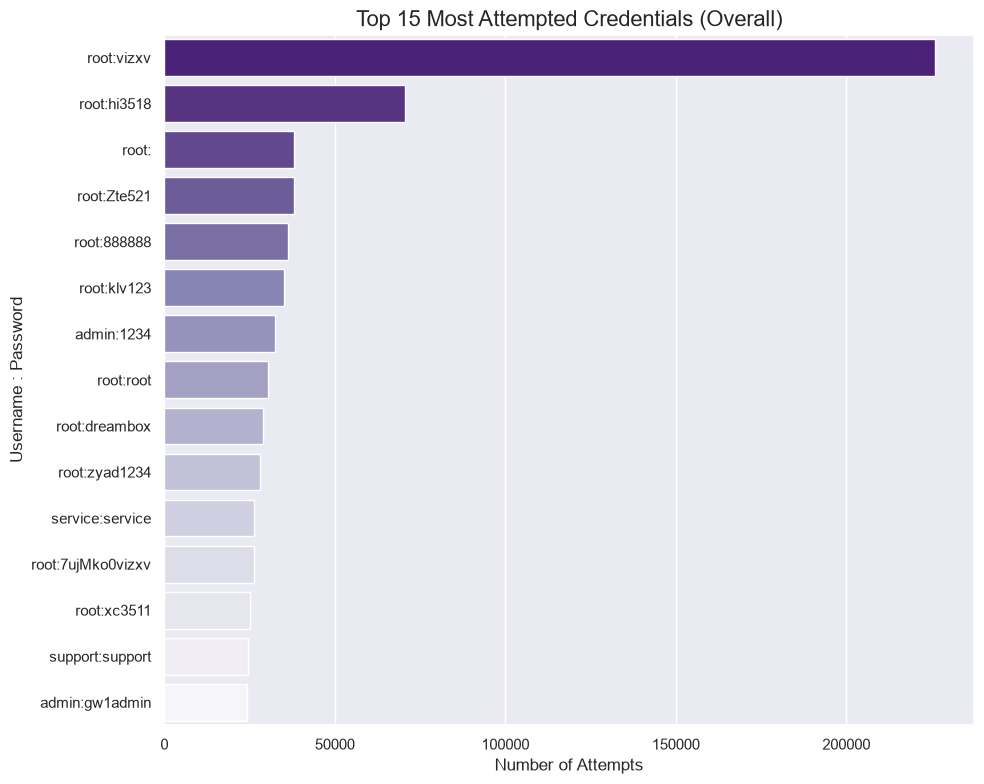

In [2]:
# Create a new column combining Username and Password
df_filtered_auth['credentials'] = df_filtered_auth['username'] + ":" + df_filtered_auth['password']

top_creds = df_filtered_auth['credentials'].value_counts().head(15) # Get top 15 most guessed creds

plt.figure(figsize=(10, 8))
sns.barplot(
    x=top_creds.values,
    y=top_creds.index,
    hue=top_creds.index,
    palette='Purples_r',
    legend=False
)

plt.title('Top 15 Most Attempted Credentials (Overall)', fontsize=16)
plt.xlabel('Number of Attempts', fontsize=12)
plt.ylabel('Username : Password', fontsize=12)
plt.tight_layout()
plt.show()

#### 3. Analyzing Sensor 2
Sensor 1 was a control sensor that accepted basic passwords (e.g., `root:password`), whereas Sensor 2 was more stringent in the credentials it accepted. It only allowed login if the attacker used specific credentials associated with IoT devices, or credentials that are hardcoded into malware families like Mirai and Gafgyt.

Targeted devices included:
* **Dahua / XiongMai IP Cameras:** `root:xc3511`, `root:vizxv`
* **Huawei HiSilicon Chips:** `root:hi3518`
* **ZTE Routers:** `root:zju68`

Let's look at the credentials *specifically* used with Sensor 2.

Total authentication attempts hitting Sensor 2: 312,373


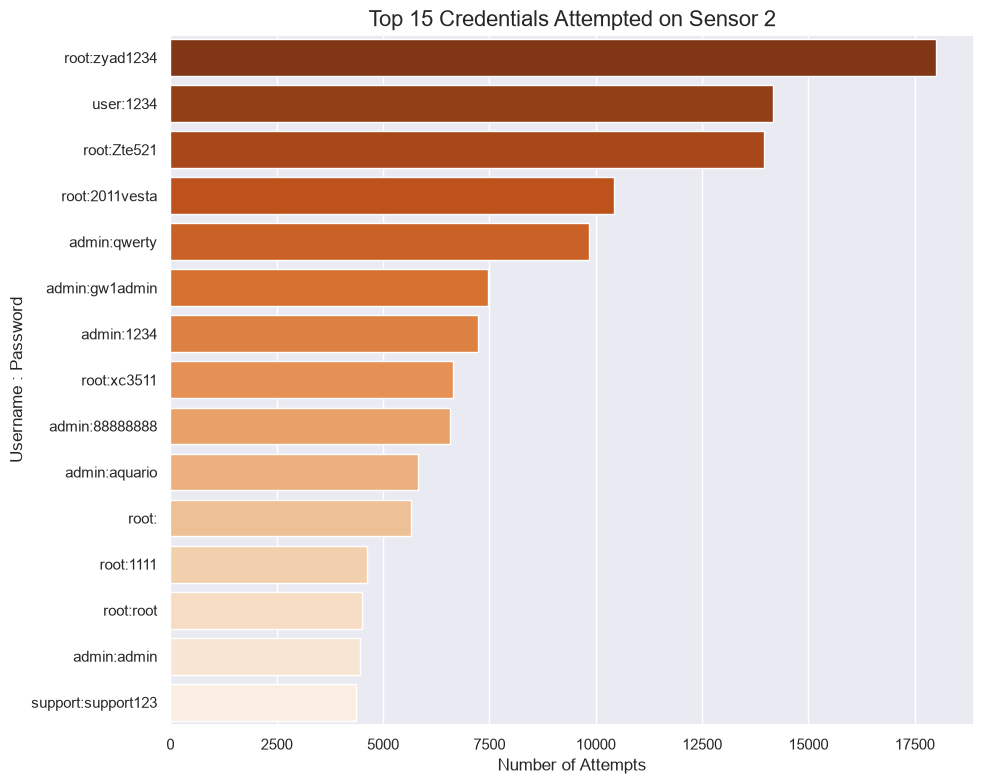

In [3]:
df_filtered_auth['sensor'] = df_filtered_auth['sensor'].astype(str) # force to string

sensor_2_auth = df_filtered_auth[df_filtered_auth['sensor'] == '2'].copy() # filter for sensor 2

print(f"Total authentication attempts hitting Sensor 2: {len(sensor_2_auth):,}")

top_creds_s2 = sensor_2_auth['credentials'].value_counts().head(15) # get top 15 creds

plt.figure(figsize=(10, 8))
sns.barplot(
    x=top_creds_s2.values,
    y=top_creds_s2.index,
    hue=top_creds_s2.index,
    palette='Oranges_r',
    legend=False
)

plt.title('Top 15 Credentials Attempted on Sensor 2', fontsize=16)
plt.xlabel('Number of Attempts', fontsize=12)
plt.ylabel('Username : Password', fontsize=12)
plt.tight_layout()
plt.show()

#### 4. Successful Logins (Sensor 2)
An attacker attempting a password is one thing, but successfully logging in is another. Because Sensor 2 had a strict password acceptance list, any `success == 1` log on this sensor guarantees the attacker was using an IoT-specific dictionary. We will now identify exactly which botnet signatures successfully breached Sensor 2.

In [4]:
# Filter for SUCCESSFUL Sensor 2 logins
successful_s2_auth = sensor_2_auth[sensor_2_auth['success'].isin([1, True, '1'])]

print(f"Total SUCCESSFUL logins on Sensor 2: {len(successful_s2_auth):,}\n")

successful_creds_s2 = successful_s2_auth['credentials'].value_counts() # count of passwords used

success_df = pd.DataFrame({
    'Credential Pair': successful_creds_s2.index,
    'Successful Logins': successful_creds_s2.values
})

display(success_df)

Total SUCCESSFUL logins on Sensor 2: 253,505



,Credential Pair,Successful Logins
0,root:zyad1234,17992
1,user:1234,14166
2,root:Zte521,13954
3,root:2011vesta,10435
4,admin:qwerty,9838
...,...,...
386,root:passwd,1
387,root:qaz123!@,1
388,root:Ab123456,1
389,root:cat1029,1


#### 5. Sensor 1 vs. Sensor 2 Comparison
Initially, we might hypothesise that automated botnets blindly "spray" the same universal credential lists across the entire internet. To test this, we compare the top 30 attempted credentials on Sensor 1 against Sensor 2 during their concurrent active windows.

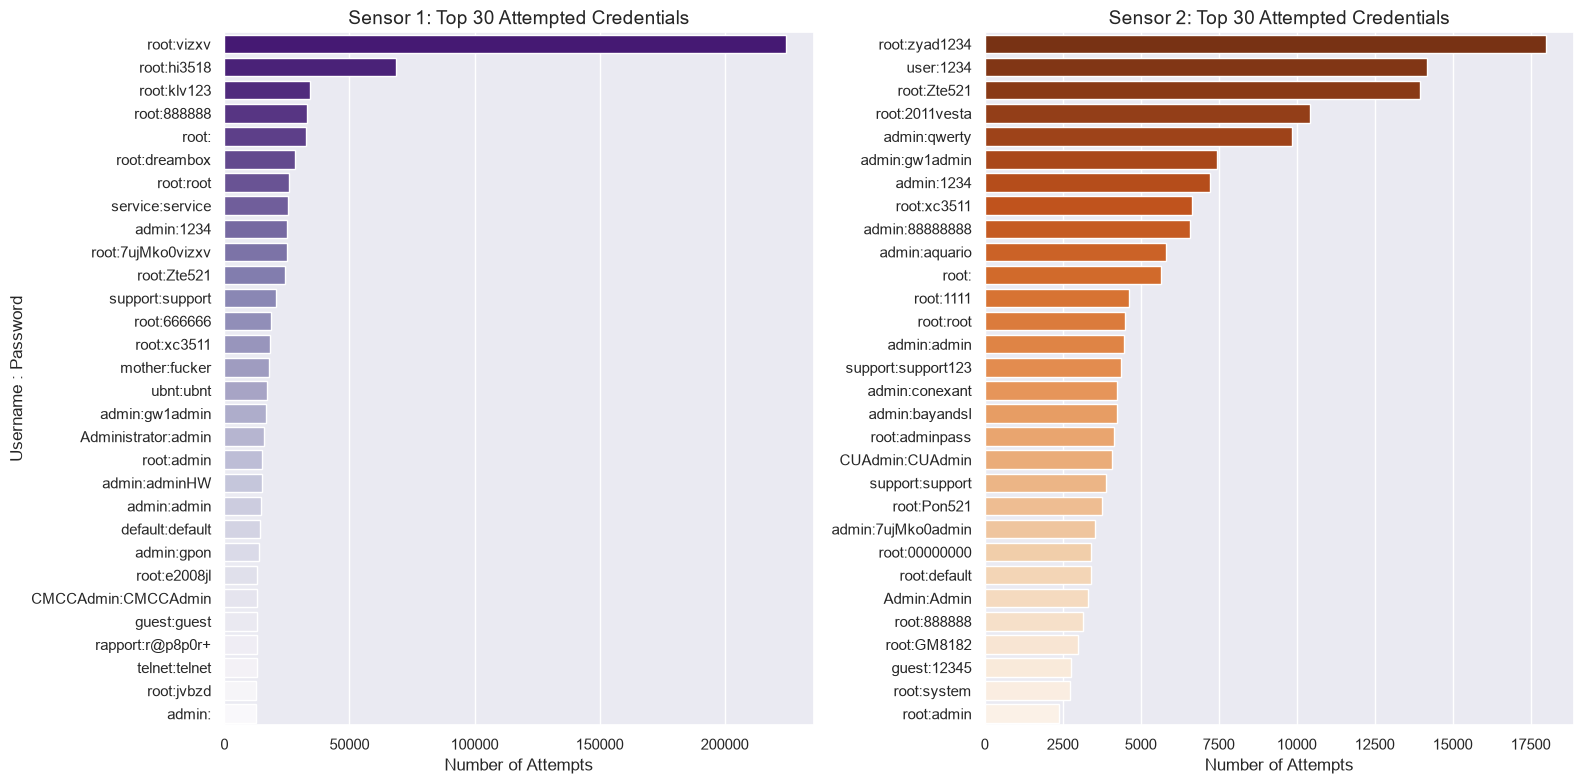

Hypothesis Test Result:
Overlap between top 30 credentials: 33.3%
Shared Credentials across both sensors:
 - root:Zte521
 - root:root
 - admin:1234
 - admin:admin
 - admin:gw1admin
 - root:admin
 - root:888888
 - support:support
 - root:
 - root:xc3511


In [5]:
sensor_1_auth = df_filtered_auth[df_filtered_auth['sensor'] == '1'].copy() # get sensor 1 data

# Get the top 30 attempted credentials for both
top_s1 = sensor_1_auth['credentials'].value_counts().head(30)
top_s2 = sensor_2_auth['credentials'].value_counts().head(30)

fig, axes = plt.subplots(1, 2, figsize=(16, 8)) # set up side by side plot

# Plot Sensor 1
sns.barplot(
    x=top_s1.values,
    y=top_s1.index,
    hue=top_s1.index,
    palette='Purples_r',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Sensor 1: Top 30 Attempted Credentials', fontsize=14)
axes[0].set_xlabel('Number of Attempts')
axes[0].set_ylabel('Username : Password')

# Plot Sensor 2
sns.barplot(
    x=top_s2.values,
    y=top_s2.index,
    hue=top_s2.index,
    palette='Oranges_r',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Sensor 2: Top 30 Attempted Credentials', fontsize=14)
axes[1].set_xlabel('Number of Attempts')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

# Calculate the overlap percentage
common_creds = set(top_s1.index).intersection(set(top_s2.index))
overlap_percent = (len(common_creds) / 30) * 100

print(f"Hypothesis Test Result:")
print(f"Overlap between top 30 credentials: {overlap_percent:.1f}%")

print("Shared Credentials across both sensors:")
for cred in common_creds:
    print(f" - {cred}")

#### Conclusion
The overlap between the top 30 credentials is only 33.3%. The low overlap could suggest that the
honeypots were targeted by distinct botnets, each relying on slightly different dictionaries. On the other
hand, this low overlap could be caused by Sensor 1 accepting more basic credentials; if an automated
script successfully authenticates early in its execution using a basic password (like root:1234), it will
immediately stop guessing, thereby preventing the IoT-specific credentials further down its list from
being logged on Sensor 1.

Additionally, this shows that the attacking scripts aren't "learning" or adapting to their environment. The botnets didn't change their guesses over time based on what credentials the sensor was actually configured to accept. They simply ran through their pre-programmed lists, blindly throwing passwords at the server regardless of the honeypot's specific rules. It would imply that the botnets aren't particularly sophisticated and are just looking for an easy target.